# Predicción de abandono de clientes de Beta Bank

## Descripción del proyecto

Los clientes de **Beta Bank** se están yendo poco a poco cada mes. Al banco le resulta más barato conservar a sus clientes que atraer nuevos.

Se construye un modelo que predice si un cliente dejará el banco pronto, a partir de su comportamiento pasado y de la terminación de contratos. La meta es alcanzar un valor **F1 de al menos 0.59** en el conjunto de prueba, y se mide también el **AUC-ROC**.

## Datos

`Churn.csv`: datos de 10 000 clientes, entre ellos puntaje crediticio, país, género, edad, antigüedad (`Tenure`), saldo, número de productos, tarjeta de crédito, actividad y salario estimado.

- Objetivo: `Exited` (1 = el cliente se fue).

## Pasos

1. Preparar los datos: codificación one-hot, división 60/20/20 estratificada e imputación de valores ausentes.
2. Analizar el desequilibrio de clases y entrenar un modelo base sin corregirlo.
3. Corregir el desequilibrio con sobremuestreo y submuestreo, y ajustar el bosque aleatorio con el conjunto de validación.
4. Evaluar el modelo final en el conjunto de prueba con F1 y AUC-ROC.

**Herramientas:** Python, pandas, NumPy, scikit-learn.

# Importar librerías

In [26]:
#Librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, accuracy_score
from sklearn.utils import shuffle
from sklearn.metrics import roc_auc_score

# 1. Cargue y preparación de datos

In [2]:
# Cargue de datos
data = pd.read_csv('/datasets/Churn.csv')
data.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2.0,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1.0,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8.0,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1.0,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2.0,125510.82,1,1,1,79084.10,0


In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           9091 non-null   float64
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(3), int64(8), object(3)
memory usage: 1.1+ MB


Separación de variable objetivo "Exited" y características

In [4]:
target = data['Exited']
features = data.drop('Exited', axis=1)

Ya que hay algunas variables categóricas, realizaré one-hot encoding para convertirlas a variables numéricas

In [5]:
features = pd.get_dummies(features, drop_first=True)

División de datos de entrenamiento(60%), validación(20%) y prueba(20%)

In [6]:
features_train, features_temp, target_train, target_temp = train_test_split(
    features,
    target,
    test_size=0.4,
    random_state=12345,
    stratify=target
)

features_valid, features_test, target_valid, target_test = train_test_split(
    features_temp,
    target_temp,
    test_size=0.5,
    random_state=12345,
    stratify=target_temp
)

print(features_train.shape)
print(features_valid.shape)
print(features_test.shape)

(6000, 2944)
(2000, 2944)
(2000, 2944)


# 2. Equilibrio de clases

In [7]:
print(target_train.value_counts())
print(target_train.value_counts(normalize=True))

0    4778
1    1222
Name: Exited, dtype: int64
0    0.796333
1    0.203667
Name: Exited, dtype: float64


<AxesSubplot:>

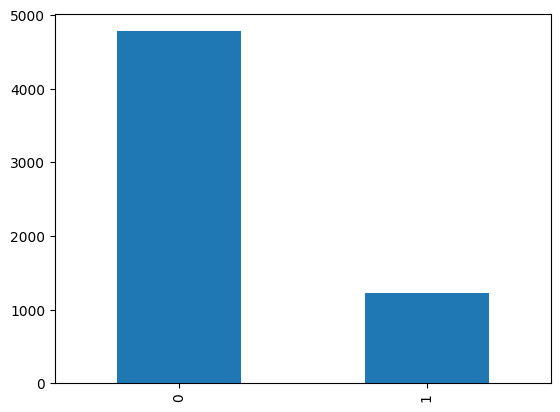

In [8]:
# Visualizarlo en grafica
target_train.value_counts().plot(kind='bar')

La columna `Tenure` tiene valores ausentes. Se rellenan con la mediana del conjunto de entrenamiento para no filtrar información de validación.

In [10]:
features_train = features_train.replace([np.inf, -np.inf], np.nan)

features_train = features_train.fillna(features_train.median())


features_valid = features_valid.replace([np.inf, -np.inf], np.nan)

features_valid = features_valid.fillna(features_train.median())


Entrenamos un modelo base, sin corregir el desequilibrio de clases.

In [11]:
model = RandomForestClassifier(
    n_estimators=100,
    random_state=12345
)

model.fit(features_train, target_train)

predicted_valid = model.predict(features_valid)

print('Accuracy:', accuracy_score(target_valid, predicted_valid))
print('F1:', f1_score(target_valid, predicted_valid))


Accuracy: 0.8605
F1: 0.5295109612141653


Se observa desequilibrio entre clases, siendo la clase 0 mucho mas frecuente que la clase 1, el modelo sin corregir este desequilibrio tiene un valor en F1 de 0.52, probaré diferentes técnicas para mejorar dicho equilibrio.

# 3. Mejorar calidad del modelo

## Upsampling

In [12]:
def upsample(features, target, repeat):
    features_zeros = features[target == 0]
    features_ones = features[target == 1]
    
    target_zeros = target[target == 0]
    target_ones = target[target == 1]

    features_upsampled = pd.concat(
        [features_zeros] + [features_ones] * repeat
    )
    
    target_upsampled = pd.concat(
        [target_zeros] + [target_ones] * repeat
    )

    features_upsampled, target_upsampled = shuffle(
        features_upsampled,
        target_upsampled,
        random_state=12345
    )

    return features_upsampled, target_upsampled

In [13]:
for repeat in [2, 3, 4, 5]:
    
    features_upsampled, target_upsampled = upsample(
        features_train,
        target_train,
        repeat
    )
    
    model = RandomForestClassifier(
        n_estimators=100,
        random_state=12345
    )
    
    model.fit(features_upsampled, target_upsampled)
    
    predicted_valid = model.predict(features_valid)
    
    print(
        'Repeat:', repeat,
        'F1:', f1_score(target_valid, predicted_valid)
    )

Repeat: 2 F1: 0.5792682926829268
Repeat: 3 F1: 0.6029411764705882
Repeat: 4 F1: 0.5693215339233038
Repeat: 5 F1: 0.581294964028777


## Downsampling

Reducción de clase mayoritaria

In [14]:
def downsample(features, target, fraction):
    features_zeros = features[target == 0]
    features_ones = features[target == 1]
    
    target_zeros = target[target == 0]
    target_ones = target[target == 1]

    features_downsampled = pd.concat([
        features_zeros.sample(
            frac=fraction,
            random_state=12345
        ),
        features_ones
    ])

    target_downsampled = pd.concat([
        target_zeros.sample(
            frac=fraction,
            random_state=12345
        ),
        target_ones
    ])

    features_downsampled, target_downsampled = shuffle(
        features_downsampled,
        target_downsampled,
        random_state=12345
    )

    return features_downsampled, target_downsampled

Probar diferentes fracciones

In [15]:
for fraction in [0.1, 0.2, 0.3, 0.4, 0.5]:
    
    features_downsampled, target_downsampled = downsample(
        features_train,
        target_train,
        fraction
    )
    
    model = RandomForestClassifier(
        n_estimators=100,
        random_state=12345
    )
    
    model.fit(features_downsampled, target_downsampled)
    
    predicted_valid = model.predict(features_valid)
    
    print(
        'Fraction:', fraction,
        'F1:', f1_score(target_valid, predicted_valid)
    )

Fraction: 0.1 F1: 0.39528929851510497
Fraction: 0.2 F1: 0.5547445255474451
Fraction: 0.3 F1: 0.6094240837696335
Fraction: 0.4 F1: 0.6307884856070088
Fraction: 0.5 F1: 0.6244952893674294


## Encontrar el mejor modelo

In [16]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score

best_f1 = 0
best_fraction = 0
best_n_estimators = 0
best_max_depth = 0

for fraction in [0.1, 0.2, 0.3, 0.4, 0.5]:
    
    features_downsampled, target_downsampled = downsample(
        features_train,
        target_train,
        fraction
    )
    
    for n_estimators in [50, 100, 150]:
        
        for max_depth in [5, 10, 15, 20]:
            
            model = RandomForestClassifier(
                n_estimators=n_estimators,
                max_depth=max_depth,
                random_state=12345
            )
            
            model.fit(features_downsampled, target_downsampled)
            
            predicted_valid = model.predict(features_valid)
            
            f1 = f1_score(target_valid, predicted_valid)
            
            if f1 > best_f1:
                best_f1 = f1
                best_fraction = fraction
                best_n_estimators = n_estimators
                best_max_depth = max_depth

print('Mejor F1:', best_f1)
print('Mejor fraction:', best_fraction)
print('Mejor n_estimators:', best_n_estimators)
print('Mejor max_depth:', best_max_depth)

Mejor F1: 0.6143024618991794
Mejor fraction: 0.3
Mejor n_estimators: 50
Mejor max_depth: 20


In [17]:
features_downsampled, target_downsampled = downsample(
    features_train,
    target_train,
    best_fraction
)

Crear el modelo con los mejores parámetros

In [18]:
best_model = RandomForestClassifier(
    n_estimators=best_n_estimators,
    max_depth=best_max_depth,
    random_state=12345
)

best_model.fit(features_downsampled, target_downsampled)

RandomForestClassifier(max_depth=20, n_estimators=50, random_state=12345)

In [19]:
predicted_valid = best_model.predict(features_valid)

print('F1 en validación:', f1_score(target_valid, predicted_valid))

F1 en validación: 0.6143024618991794


# 4. Prueba final

Antes de evaluar en el conjunto de prueba, se revisan sus valores ausentes.

In [21]:
#Validacion de datos faltantes

print(features_test.isna().sum())

RowNumber              0
CustomerId             0
CreditScore            0
Age                    0
Tenure               183
                    ... 
Surname_Zuyev          0
Surname_Zuyeva         0
Geography_Germany      0
Geography_Spain        0
Gender_Male            0
Length: 2944, dtype: int64


In [22]:
print('Train:')
print(features_train.isna().sum().sum())

print('Valid:')
print(features_valid.isna().sum().sum())

print('Test:')
print(features_test.isna().sum().sum())

Train:
0
Valid:
0
Test:
183


de nuevo rellenaremos los valores NaN con la mediana

In [23]:
median_tenure = features_train['Tenure'].median()

features_test['Tenure'] = features_test['Tenure'].fillna(median_tenure)

In [24]:
print(features_test['Tenure'].isna().sum())

0


In [25]:
predicted_test = best_model.predict(features_test)

print('Accuracy en el conjunto de prueba:', accuracy_score(target_test, predicted_test))
print('F1 en el conjunto de prueba:', f1_score(target_test, predicted_test))

Accuracy en el conjunto de prueba: 0.82
F1 en el conjunto de prueba: 0.5631067961165049


In [27]:
probabilities_test = best_model.predict_proba(features_test)[:, 1]

auc_roc = roc_auc_score(target_test, probabilities_test)

print('AUC-ROC:', auc_roc)

AUC-ROC: 0.81685537617741


# Conclusiones

Durante el proyecto se desarrolló un modelo para predecir el abandono de clientes. Se prepararon los datos con codificación one-hot, se dividieron en entrenamiento, validación y prueba, y se imputaron los valores ausentes de `Tenure` con la mediana del entrenamiento.

El conjunto presenta un desequilibrio de clases: solo cerca del 20 % de los clientes abandonó el banco. Por eso la exactitud no es una métrica adecuada y se usaron F1 y AUC-ROC.

- El modelo base, sin corregir el desequilibrio, obtuvo un F1 de **0.53** en validación.
- Con **submuestreo** (conservando el 30 % de la clase mayoritaria) y un bosque aleatorio con `n_estimators=50` y `max_depth=20`, el F1 en validación subió a **0.61**.
- En el conjunto de prueba, el modelo obtuvo un F1 de **0.56**, una exactitud de **0.82** y un AUC-ROC de **0.82**.

El F1 en prueba queda por debajo de la meta de 0.59, aunque el AUC-ROC indica que el modelo ordena bien a los clientes según su riesgo de abandono y puede usarse para priorizar campañas de retención.

**Próximos pasos:** eliminar las columnas identificadoras (`RowNumber`, `CustomerId`, `Surname`), que generan miles de columnas sin valor predictivo, y ajustar el umbral de clasificación para mejorar el F1.